# Where degradation costs time, all dry 2025 races

The Bahrain case study was finished and its result known before telemetry for the other 2025 races was downloaded. The same procedure was repeated race by race with no change, and the plan is in `PREREGISTRATION_TELEMETRY_SEASON.md`. The primary metric T1 is the mean over races of the density difference G for the compound with the most kept laps. G is the fitted degradation per second of lap time in corner mini-sectors minus the same on straight mini-sectors.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as cfg
import expansion_config as xc
import f1deg as F
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
COL = {"SOFT": "#d93025", "MEDIUM": "#c79a00", "HARD": "#4a4f57"}

from pathlib import Path
base = Path("results/telemetry_season")
q = pd.read_csv("results/telemetry_season_quality.csv")
rc = pd.read_csv(base / "race_compound.csv")
sm = pd.read_csv(base / "summary.csv")
lin = pd.read_csv(base / "linearity.csv")
print(q.round(3).to_string(index=False))

 round                     event load_status  clean_laps  kept  dropped  mismatch_mean  mismatch_median  mismatch_max  compounds_dropped_after_mismatch
     2        Chinese Grand Prix          ok         944   940        4          0.309            0.292         1.093                               NaN
     3       Japanese Grand Prix          ok         996   989        7          0.308            0.282         1.355                               NaN
     4        Bahrain Grand Prix          ok         951   945        6          0.313            0.293         1.123                               NaN
     5  Saudi Arabian Grand Prix          ok         803   796        7          0.308            0.284         1.457                               NaN
     6          Miami Grand Prix          ok         551   545        6          0.299            0.268         1.313                               NaN
     7 Emilia Romagna Grand Prix          ok         924   916        8          0.305  

## Data quality
Laps with a mismatch above the limit between the summed mini-sector times and the official lap time were dropped. The mismatch statistics include those laps.

In [2]:
print("races fitted:", rc["round"].nunique(), " max linearity difference:", lin["abs_difference"].max())
print(sm.round(6).to_string(index=False))

races fitted: 21  max linearity difference: 9.228728892196614e-16
                 metric     value       lo       hi  n                                                                             note
                     T1  0.000384 0.000250 0.000525 21                                                                              NaN
             races_used 21.000000      NaN      NaN 21                                                                              NaN
       races_G_positive 19.000000      NaN      NaN 21                                                                              NaN
        density_BRAKING  0.000704 0.000547 0.000868 21 mean over races, primary compound, seconds of degradation per second of lap time
density_CORNER_NO_BRAKE  0.000495 0.000339 0.000645 21 mean over races, primary compound, seconds of degradation per second of lap time
       density_STRAIGHT  0.000262 0.000182 0.000361 21 mean over races, primary compound, seconds of degradation per s

## G per race and T1

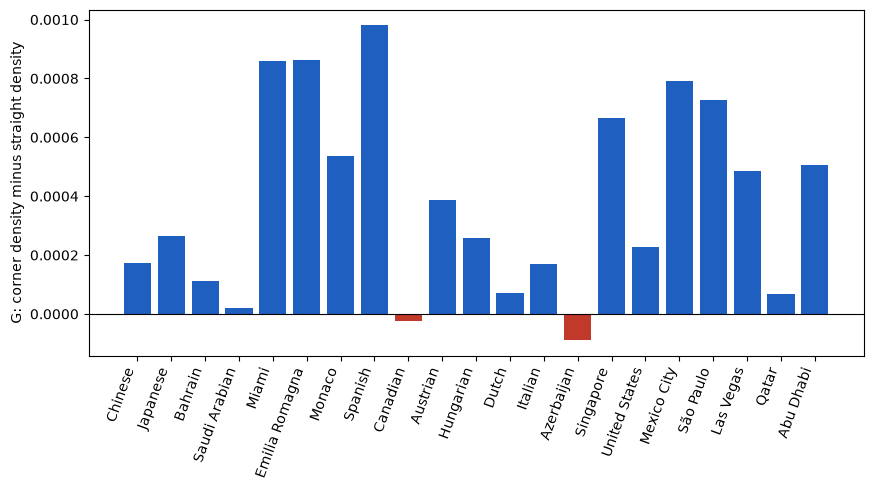

T1 = 0.000384, indicative interval 0.000250 to 0.000525, races 21
races with G above zero: 19


In [3]:
p = rc[rc["is_primary"]].copy()
p["event"] = p["event"].str.replace(" Grand Prix", "")
u = p[p["G"].notna()].sort_values("round")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(len(u)), u["G"], color=["#1f5fbf" if g > 0 else "#c0392b" for g in u["G"]])
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(u))); ax.set_xticklabels(u["event"], rotation=70, ha="right")
ax.set_ylabel("G: corner density minus straight density")
fig.savefig("Images/telemetry_density_by_race.png", dpi=150, bbox_inches="tight")
plt.show()
t1 = sm[sm["metric"] == "T1"].iloc[0]
print(f"T1 = {t1['value']:.6f}, indicative interval {t1['lo']:.6f} to {t1['hi']:.6f}, races {int(t1['n'])}")
print("races with G above zero:", int((u["G"] > 0).sum()))

## The three-class densities
BRAKING if the reference lap braked in the mini-sector, otherwise CORNER_NO_BRAKE if the minimum throttle was below the threshold, otherwise STRAIGHT.

                 metric    value       lo       hi  n                                                                             note
        density_BRAKING 0.000704 0.000547 0.000868 21 mean over races, primary compound, seconds of degradation per second of lap time
density_CORNER_NO_BRAKE 0.000495 0.000339 0.000645 21 mean over races, primary compound, seconds of degradation per second of lap time
       density_STRAIGHT 0.000262 0.000182 0.000361 21 mean over races, primary compound, seconds of degradation per second of lap time


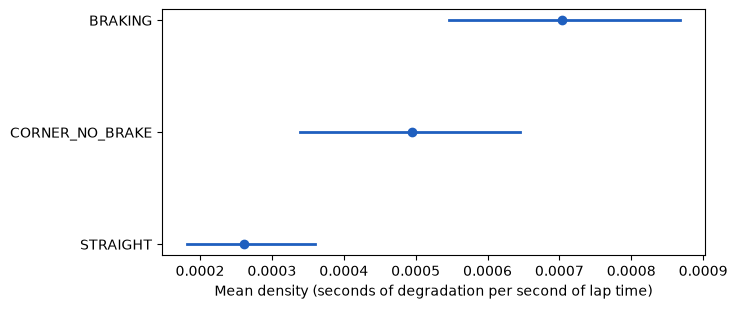

In [4]:
d3 = sm[sm["metric"].str.startswith("density_")]
print(d3.round(6).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 3.2))
for i, (_, r) in enumerate(d3.iterrows()):
    ax.plot([r["lo"], r["hi"]], [i, i], color="#1f5fbf", lw=2)
    ax.plot(r["value"], i, "o", color="#1f5fbf")
ax.set_yticks(range(len(d3))); ax.set_yticklabels([m.replace("density_", "") for m in d3["metric"]]); ax.invert_yaxis()
ax.set_xlabel("Mean density (seconds of degradation per second of lap time)")
fig.savefig("Images/telemetry_class3.png", dpi=150, bbox_inches="tight")
plt.show()

## Two track maps
The races with the largest and the smallest G, picked by rule.

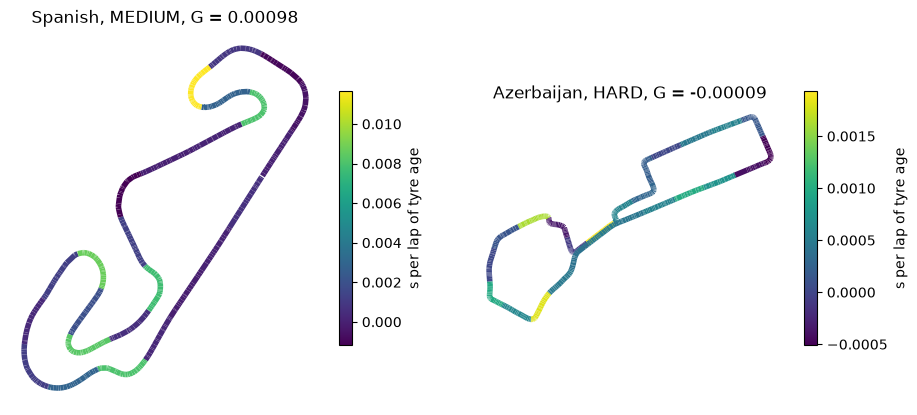

In [5]:
from matplotlib.collections import LineCollection
pp = u.sort_values("G")
picks = [pp.iloc[-1], pp.iloc[0]]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, r in zip(axes, picks):
    rr = f"{int(r['round']):02d}"
    ref = pd.read_csv(f"data/reference_laps_2025/{rr}.csv")
    fits = pd.read_csv(base / f"minisector_fits_{rr}.csv")
    rate = fits[f"deg_rate_{r['compound']}"].to_numpy()
    pts = np.column_stack([ref["X"], ref["Y"]]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    lc = LineCollection(segs, cmap="viridis", linewidth=4)
    lc.set_array(rate[ref["minisector"].to_numpy()[:-1]])
    ax.add_collection(lc); ax.autoscale(); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{r['event']}, {r['compound']}, G = {r['G']:.5f}")
    fig.colorbar(lc, ax=ax, shrink=0.6, label="s per lap of tyre age")
fig.savefig("Images/telemetry_two_maps.png", dpi=150, bbox_inches="tight")
plt.show()

## What this shows and what it does not
The pre-registered metric T1 is positive and its indicative interval is above zero. In 19 of 21 races, the fitted degradation per second of lap time is higher in corner mini-sectors than on straight mini-sectors for the compound with the most kept laps. The three-class densities are in the same order: braking mini-sectors are highest, corners without braking are in the middle and straights are lowest.

This is one season. The fitted values are under this model, mini-sector borders come from integrated speed and shift slightly from lap to lap, and the class labels come from one reference lap per race. The result says nothing about other seasons or other tyre ranges.